# Entrega 3 · Modelado — Pronóstico dinámico de réplicas (`Opción 1: Horizontes con actividad temprana`)

Ciencia de Datos · UTN FRM · 2026

**Pregunta del proyecto reformulada:**
> *Dado que un sismo principal ya registró actividad de réplicas en las primeras $t$ horas (`n_aft_t > 0`, con $t \in \{1, 6, 24, 72, 168\}\text{ h}$), ¿cuántas réplicas **adicionales** (`y_aft`) ocurrirán hasta completar los 30 días?*

### Qué cambió respecto del planteo inicial
Reformulamos el objetivo pasando de la tabla de sismos estáticos en $t=0$ (donde el 89,4 % no registraba réplicas y el piso trivial de predecir cero era imbatible) a una tabla dinámica de horizontes temporales condicionada a secuencias que ya evidenciaron actividad temprana ($n_{\text{aft}, t} > 0$). De este modo predecimos las réplicas restantes en tiempo real ($1, 6, 24, 72, 168\text{ h}$) utilizando variables causales observadas estrictamente hasta ese instante.

# 1. Configuración y carga del dataset (Local y Google Colab)

Definimos una única semilla global (`SEMILLA = 42`) que se pasa a todas las particiones y modelos. El bloque de carga detecta automáticamente si el notebook está corriendo en el repositorio local o en Google Colab.

In [1]:
import os
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 35)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.3f}".format)

SEMILLA = 42
np.random.seed(SEMILLA)

NOMBRE_CLUSTERS = "clusters_combined_5regions-c4d8c04f_mainshock=largest_seed=1.csv"
NOMBRE_HORIZONS = "horizons_combined_5regions-c4d8c04f_mainshock=largest_seed=1.csv"

# IDs opcionales de Google Drive por si se ejecuta en Google Colab sin subir archivos manualmente
ID_DRIVE_CLUSTERS = ""  # Completar si se usa gdown en Colab
ID_DRIVE_HORIZONS = ""  # Completar si se usa gdown en Colab

def resolver_archivo(nombre_archivo: str, id_drive: str = "") -> Path:
    """Busca el CSV en rutas locales del proyecto; si no está (ej. Colab), lo descarga o pide subirlo."""
    rutas_locales = [
        Path(nombre_archivo),
        Path("..") / "pipeline" / "include" / "output" / "detector_replicas_api" / "delivery" / nombre_archivo,
        Path("pipeline") / "include" / "output" / "detector_replicas_api" / "delivery" / nombre_archivo,
    ]
    for ruta in rutas_locales:
        if ruta.exists():
            print(f"[Local] Archivo encontrado en: {ruta.resolve()}")
            return ruta

    # Caso Google Colab
    if id_drive:
        os.system(f"gdown {id_drive} -O {nombre_archivo}")
        if Path(nombre_archivo).exists():
            return Path(nombre_archivo)

    try:
        from google.colab import files  # type: ignore
        print(f"[Colab] Subí el archivo '{nombre_archivo}' desde tu computadora:")
        files.upload()
        return Path(nombre_archivo)
    except ImportError:
        raise FileNotFoundError(
            f"No se encontró '{nombre_archivo}' en las rutas locales ni se configuró ID_DRIVE."
        )

ruta_clusters = resolver_archivo(NOMBRE_CLUSTERS, ID_DRIVE_CLUSTERS)
ruta_horizons = resolver_archivo(NOMBRE_HORIZONS, ID_DRIVE_HORIZONS)

[Local] Archivo encontrado en: C:\Users\nicoo\dev\Python\Ciencia de datos\ciencia-datos-sismos\pipeline\include\output\detector_replicas_api\delivery\clusters_combined_5regions-c4d8c04f_mainshock=largest_seed=1.csv
[Local] Archivo encontrado en: C:\Users\nicoo\dev\Python\Ciencia de datos\ciencia-datos-sismos\pipeline\include\output\detector_replicas_api\delivery\horizons_combined_5regions-c4d8c04f_mainshock=largest_seed=1.csv


In [2]:
clusters_raw = pd.read_csv(ruta_clusters, low_memory=False)
horizons_raw = pd.read_csv(ruta_horizons, low_memory=False)

clusters_raw["mainshock_time"] = pd.to_datetime(clusters_raw["mainshock_time"], format="ISO8601", utc=True)

# Columnas causales del sismo principal (conocidas en t = 0) que agregamos a la tabla de horizontes
COLS_CLUSTER_CAUSALES = [
    "cluster_id",
    "mainshock_id",
    "mainshock_place",
    "mainshock_time",
    "mainshock_mag",
    "mainshock_depth",
    "mainshock_lat",
    "mainshock_lon",
    "dist_to_border_km",
    "near_border",
    "region_mc",
    "region_log10_eta0",
    "n_prior_2d",
    "n_prior_30d",
    "n_prior_365d",
    "prior_max_mag_365d",
    "days_since_prior",
    "prior_window_truncated",
]

df_merged = horizons_raw.merge(clusters_raw[COLS_CLUSTER_CAUSALES], on="cluster_id", how="left")

# Opción 1: Secuencias no censuradas a 30 días (~censored_T) y con actividad observada hasta t (n_aft_t > 0)
df = (
    df_merged[(~df_merged["censored_T"]) & (df_merged["n_aft_t"] > 0)]
    .sort_values(["mainshock_time", "cluster_id", "horizon_hours"])
    .reset_index(drop=True)
)

pd.Series({
    "filas_horizons_totales": len(horizons_raw),
    "filas_opcion1 (n_aft_t > 0 y no censuradas)": len(df),
    "secuencias_unicas (cluster_id)": df["cluster_id"].nunique(),
    "horizontes_evaluados_h": str(sorted(df["horizon_hours"].unique().tolist())),
    "columnas_totales": df.shape[1],
})

filas_horizons_totales                                       97850
filas_opcion1 (n_aft_t > 0 y no censuradas)                   6719
secuencias_unicas (cluster_id)                                1767
horizontes_evaluados_h                         [1, 6, 24, 72, 168]
columnas_totales                                                28
dtype: object

Partiendo de las **97.850 filas** de la tabla completa de horizontes (19.570 secuencias × 5 cortes horarios), al filtrar las secuencias cuya ventana de 30 días está completa en el catálogo (`~censored_T`) y que ya registraron al menos una réplica hasta el instante de evaluación (`n_aft_t > 0`), obtenemos un dataset de **6.719 filas (evaluaciones)** correspondientes a **1.767 secuencias sísmicas únicas (`cluster_id`)** a lo largo de los 5 horizontes horarios (`1, 6, 24, 72 y 168 horas`) y **28 columnas**.

# 2. Qué predecimos (`y_aft`) y control de fuga de información

Para cada fila `(cluster_id, horizon_hours)`, estamos parados exactamente a $t = \text{horizon\_hours}$ horas después del sismo principal:
- **Lo que ya pasó (disponible en $t$):** las características del sismo principal ($t=0$) y las réplicas observadas entre $0$ y $t$ (`n_aft_t`, `max_aft_mag_t`, `hours_since_last_t`).
- **La variable objetivo (`y_aft`):** la cantidad de réplicas que ocurrirán en el futuro, entre la hora $t$ y el cierre de la ventana de $T = 30\text{ días}$.

Veamos cómo cambia la distribución de `y_aft` según el horizonte horario $t$:

In [3]:
resumen_horizontes = (
    df.groupby("horizon_hours")["y_aft"]
    .agg(
        filas="size",
        pct_ceros=lambda s: round((s == 0).mean() * 100, 1),
        pct_sigue_activa=lambda s: round((s > 0).mean() * 100, 1),
        media="mean",
        mediana="median",
        p75=lambda s: s.quantile(0.75),
        p90=lambda s: s.quantile(0.90),
        maximo="max",
    )
    .round(2)
)
resumen_global = pd.DataFrame(
    {
        "filas": [len(df)],
        "pct_ceros": [round((df["y_aft"] == 0).mean() * 100, 1)],
        "pct_sigue_activa": [round((df["y_aft"] > 0).mean() * 100, 1)],
        "media": [round(df["y_aft"].mean(), 2)],
        "mediana": [df["y_aft"].median()],
        "p75": [df["y_aft"].quantile(0.75)],
        "p90": [df["y_aft"].quantile(0.90)],
        "maximo": [df["y_aft"].max()],
    },
    index=["TODOS (pool)"],
)
pd.concat([resumen_horizontes, resumen_global])

,filas,pct_ceros,pct_sigue_activa,media,mediana,p75,p90,maximo
1,755,53.200,46.800,9.870,0.000,3.000,10.000,1694
6,1122,61.900,38.100,5.900,0.000,1.000,5.000,1542
24,1431,71.300,28.700,3.530,0.000,1.000,3.000,1235
72,1644,79.400,20.600,2.030,0.000,0.000,2.000,834
168,1767,86.200,13.800,1.180,0.000,0.000,1.000,520
TODOS (pool),6719,73.600,26.400,3.650,0.000,1.000,3.000,1694


La tabla refleja con claridad el decaimiento temporal de la **Ley de Omori**:
- A **$t = 1\text{ h}$** (`755` secuencias activas), el **46,8 %** seguirá generando nuevas réplicas antes de los 30 días (frente a un 53,2 % que ya no tendrá más eventos), con un promedio de **9,87 réplicas restantes** (percentil 75 de 3 réplicas, percentil 90 de 10 réplicas y un máximo de 1.694).
- A **$t = 6\text{ h}$** (`1.122` secuencias), el **38,1 %** continúa activo con una media de **5,90 réplicas restantes**.
- A medida que avanza el horizonte hacia **$24\text{ h}$, $72\text{ h}$ y $168\text{ h}$ (7 días)**, la proporción de secuencias que siguen activas desciende monótonamente al **28,7 %**, **20,6 %** y **13,8 %**, y la media de réplicas por ocurrir cae a **3,53**, **2,03** y **1,18** respectivamente.
- En el conjunto combinado (**6.719 evaluaciones**), el **26,4 %** de las filas presenta réplicas futuras (`73,6 %` de ceros, reduciendo drásticamente el 89,4 % de ceros que tenía el dataset estático en $t = 0$) con una media global de **3,65 réplicas**.

## Columnas que NO pueden entrar al modelo (chequeo de fuga)

Separamos explícitamente:
1. **`FUGA`:** columnas que contienen información posterior a la hora $t$ (como `n_aft_T = n_aft_t + y_aft`, `y_has_aft`, o las métricas finales del cluster completo como `n_aftershocks`, `duration_days`, `extent_km`).
2. **`IDS`:** identificadores, fechas y banderas de censura que se usan para partir o auditar los datos, pero no como predictores.
3. **`CANDIDATAS`:** únicamente columnas que existen y son observables en el instante $t$.

In [4]:
FUGA = [
    "y_aft",          # Es la variable objetivo (réplicas entre t y T=30 días)
    "y_has_aft",      # Es la variable objetivo binarizada (y_aft > 0)
    "n_aft_T",        # Fuga directa: n_aft_T = n_aft_t + y_aft (contiene la respuesta exacta)
]

IDS = [
    "cluster_id",     # Identificador de la secuencia (se usa como grupo en GroupKFold)
    "mainshock_id",
    "mainshock_place",
    "mainshock_time", # Se usa para ordenar y separar train/test cronológicamente
    "censored_T",
    "censored_t",
]

# Columnas estrictamente causales en el instante t = horizon_hours
CANDIDATAS = [
    # Observadas entre t=0 y t=horizon_hours
    "horizon_hours",
    "n_aft_t",
    "max_aft_mag_t",
    "hours_since_last_t",
    # Conocidas en t=0 (sismo principal y contexto regional)
    "mainshock_mag",
    "mainshock_depth",
    "mainshock_lat",
    "mainshock_lon",
    "dist_to_border_km",
    "region",
    "region_mc",
    # Sismicidad previa a t=0 (ventana histórica antes del principal)
    "n_prior_2d",
    "n_prior_30d",
    "n_prior_365d",
    "prior_max_mag_365d",
    "days_since_prior",
]

# Verificamos que ninguna columna prohibida esté en CANDIDATAS
assert set(CANDIDATAS).isdisjoint(FUGA + IDS), "Error: hay columnas de fuga o IDs en CANDIDATAS"

X = df[CANDIDATAS].copy()
y = df["y_aft"].astype(float).copy()
grupos = df["cluster_id"].copy()

print("Nulos por columna en X:")
print(X.isna().sum()[X.isna().sum() > 0])
X.head(5)

Nulos por columna en X:
prior_max_mag_365d    346
days_since_prior       87
dtype: int64


,horizon_hours,n_aft_t,max_aft_mag_t,hours_since_last_t,mainshock_mag,mainshock_depth,mainshock_lat,mainshock_lon,dist_to_border_km,region,region_mc,n_prior_2d,n_prior_30d,n_prior_365d,prior_max_mag_365d,days_since_prior
0,24,1,4.200,5.314,4.200,90.500,16.632,-95.735,485.699,mexico_ca,4.200,0,0,0,NaN,NaN
1,72,1,4.200,53.314,4.200,90.500,16.632,-95.735,485.699,mexico_ca,4.200,0,0,0,NaN,NaN
2,168,1,4.200,149.314,4.200,90.500,16.632,-95.735,485.699,mexico_ca,4.200,0,0,0,NaN,NaN
3,1,1,4.800,0.919,6.000,10.000,15.651,119.658,284.590,philippines,4.700,0,0,0,NaN,NaN
4,6,1,4.800,5.919,6.000,10.000,15.651,119.658,284.590,philippines,4.700,0,0,0,NaN,NaN


Verificamos dos propiedades importantes de la matriz de predictores `X`:
1. **`max_aft_mag_t` tiene 0 nulos:** en la tabla de horizontes sin filtrar, esta columna tenía más de un 90 % de nulos estructurales porque no existe magnitud máxima cuando `n_aft_t == 0`. Al condicionar el problema a secuencias con actividad iniciada (`n_aft_t > 0`), siempre existe al menos una réplica observada hasta $t$ y el nulo estructural desaparece por completo.
2. **Únicos nulos presentes:** sólo aparecen en las variables históricas previas a $t = 0$, `prior_max_mag_365d` (**346 filas**, 5,1 %) y `days_since_prior` (**87 filas**, 1,3 %), cuando un sismo principal ocurrió en una zona sin actividad previa registrada en el último año o desde el inicio del catálogo. Estos faltantes se imputan dentro del `Pipeline` usando exclusivamente estadísticas de entrenamiento.

# 3. Cómo partimos los datos: corte temporal por secuencia y `GroupKFold`

En esta tabla larga tenemos **dos dependencias** que debemos respetar para no hacer trampa:
1. **Orden temporal entre sismos:** queremos usar sismos pasados para predecir sismos futuros. Por eso separamos **Entrenamiento (80 % de las secuencias más antiguas)** y **Test (20 % de las secuencias más recientes)** ordenando por `mainshock_time`.
2. **Repetición por entidad (`cluster_id`):** un mismo terremoto tiene hasta 5 filas en el dataset ($t = 1, 6, 24, 72, 168\text{ h}$). Si un mismo `cluster_id` quedara partido entre entrenamiento y validación (o entre entrenamiento y test), el modelo estaría viendo otras horas del mismo terremoto. Por eso:
   - El corte 80/20 entre *Train* y *Test* se hace **por secuencias completas (`cluster_id`)**.
   - Dentro de *Train*, la validación cruzada se arma con **`GroupKFold(n_splits=5)` pasando `groups=grupos_train` (`cluster_id`)**, de modo que todas las horas de un mismo terremoto caigan siempre del mismo lado.

In [5]:
# Ordenamos los clusters únicos cronológicamente por el momento de su sismo principal
clusters_ordenados = (
    df.groupby("cluster_id", as_index=False)["mainshock_time"]
    .min()
    .sort_values("mainshock_time")
    .reset_index(drop=True)
)

n_clusters_train = int(len(clusters_ordenados) * 0.80)
clusters_train_set = set(clusters_ordenados["cluster_id"].iloc[:n_clusters_train])

mascara_train = df["cluster_id"].isin(clusters_train_set).to_numpy()

X_train, X_test = X.loc[mascara_train].copy(), X.loc[~mascara_train].copy()
y_train, y_test = y.loc[mascara_train].copy(), y.loc[~mascara_train].copy()
grupos_train = grupos.loc[mascara_train].copy()
grupos_test = grupos.loc[~mascara_train].copy()

# Verificación estricta: 0 clusters compartidos entre train y test
assert set(grupos_train).isdisjoint(set(grupos_test)), "Fuga: hay cluster_id compartidos entre train y test"

pd.DataFrame(
    {
        "filas (evaluaciones)": [len(X_train), len(X_test)],
        "secuencias únicas (cluster_id)": [grupos_train.nunique(), grupos_test.nunique()],
        "desde": [
            df.loc[mascara_train, "mainshock_time"].min().date(),
            df.loc[~mascara_train, "mainshock_time"].min().date(),
        ],
        "hasta": [
            df.loc[mascara_train, "mainshock_time"].max().date(),
            df.loc[~mascara_train, "mainshock_time"].max().date(),
        ],
        "% con más réplicas (y_aft > 0)": [
            round((y_train > 0).mean() * 100, 1),
            round((y_test > 0).mean() * 100, 1),
        ],
        "media y_aft": [round(y_train.mean(), 2), round(y_test.mean(), 2)],
        "mediana y_aft": [y_train.median(), y_test.median()],
    },
    index=["entrenamiento (80% clusters)", "test (20% clusters)"],
)

,filas (evaluaciones),secuencias únicas (cluster_id),desde,hasta,% con más réplicas (y_aft > 0),media y_aft,mediana y_aft
entrenamiento (80% clusters),5345,1413,2003-01-01,2021-08-17,26.300,4.190,0.000
test (20% clusters),1374,354,2021-08-18,2025-11-18,26.900,1.560,0.000


La partición temporal por secuencia completa divide el dataset sin filtrar información entre ambos conjuntos (`0` `cluster_id` compartidos):
- **Entrenamiento (80 % de los clusters más antiguos):** contiene **5.345 evaluaciones** de **1.413 secuencias únicas**, ocurridas entre el **1 de enero de 2003 y el 17 de agosto de 2021**. El **26,3 %** de las filas tiene réplicas posteriores (`y_aft > 0`), con una media de **4,19 réplicas**.
- **Test (20 % de los clusters más recientes):** contiene **1.374 evaluaciones** de **354 secuencias únicas**, ocurridas entre el **18 de agosto de 2021 y el 18 de noviembre de 2025**. La proporción de secuencias que continúan activas se mantiene sumamente estable (**26,9 %** en test frente a **26,3 %** en entrenamiento), mientras que la media es menor (**1,56 réplicas**) debido a que en el período 2021–2025 no ocurrieron megasismos de magnitud $M \ge 8.8$ como los de Maule 2010 o Tohoku 2011 presentes en el entrenamiento.
- A su vez, la tabla de los 5 folds de `GroupKFold` confirma que cada fold valida sobre **1.069 filas** (**282 a 283 secuencias únicas**) con **0 clusters compartidos** entre entrenamiento y validación.

In [6]:
from sklearn.model_selection import GroupKFold

cv = GroupKFold(n_splits=5)

pd.DataFrame(
    [
        {
            "filas_train": len(idx_tr),
            "filas_val": len(idx_val),
            "clusters_val": grupos_train.iloc[idx_val].nunique(),
            "clusters_compartidos": len(
                set(grupos_train.iloc[idx_tr]).intersection(set(grupos_train.iloc[idx_val]))
            ),
            "media_y_val": round(y_train.iloc[idx_val].mean(), 2),
        }
        for idx_tr, idx_val in cv.split(X_train, y_train, groups=grupos_train)
    ],
    index=[f"fold {i + 1}" for i in range(5)],
)

,filas_train,filas_val,clusters_val,clusters_compartidos,media_y_val
fold 1,4276,1069,282,0,8.580
fold 2,4276,1069,282,0,2.170
fold 3,4276,1069,283,0,4.480
fold 4,4276,1069,283,0,2.220
fold 5,4276,1069,283,0,3.510


# 4. La métrica de evaluación y el Pipeline sin fuga

### Por qué modelamos `log1p(y_aft)` y cómo medimos el error
La productividad de réplicas sigue una ley exponencial con la magnitud (Ley de Utsu: $N \propto 10^{\alpha M}$): la mayoría de las evaluaciones tiene entre 0 y 10 réplicas restantes, pero unos pocos megasismos superan las 1.000 réplicas.
- Si entrenamos un regresor minimizando el error cuadrático sobre el conteo crudo, **tres megasismos dominan toda la función de pérdida**.
- Por eso encapsulamos cada regresor en `TransformedTargetRegressor(func=np.log1p, inverse_func=expm1_clip)` para aprender sobre $\log(1 + y_{\text{aft}})$ y evaluamos con tres métricas complementarias:
  1. **`MAE_log` (métrica principal de decisión):** Error Absoluto Medio en escala $\log(1 + y_{\text{aft}})$. Penaliza proporcionalmente el orden de magnitud y evita que un solo evento extremo distorsione la elección del modelo.
  2. **`R2_log`:** Proporción de la varianza de $\log(1 + y_{\text{aft}})$ explicada por el modelo.
  3. **`MAE_replicas`:** Error Absoluto Medio expresado directamente en **unidades de réplicas** ($|\text{real} - \text{predicho}|$), junto con el porcentaje de aciertos dentro de $\pm 1$ réplica.

In [7]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, make_scorer, r2_score
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


def expm1_no_negativo(y_log):
    """Inversa de log1p truncada a [0, +inf) para garantizar conteos no negativos."""
    return np.expm1(np.clip(y_log, 0.0, 15.0))


def mae_en_log(y_real, y_pred_replicas):
    return mean_absolute_error(np.log1p(y_real), np.log1p(np.clip(y_pred_replicas, 0.0, None)))


def r2_en_log(y_real, y_pred_replicas):
    return r2_score(np.log1p(y_real), np.log1p(np.clip(y_pred_replicas, 0.0, None)))


def mae_en_replicas(y_real, y_pred_replicas):
    return mean_absolute_error(y_real, np.clip(y_pred_replicas, 0.0, None))


def acierto_pm1(y_real, y_pred_replicas):
    pred_int = np.rint(np.clip(y_pred_replicas, 0.0, None))
    return float((np.abs(y_real - pred_int) <= 1.0).mean() * 100.0)


SCORERS = {
    "mae_log": make_scorer(mae_en_log, greater_is_better=False),
    "r2_log": make_scorer(r2_en_log),
    "mae_rep": make_scorer(mae_en_replicas, greater_is_better=False),
    "pm1_pct": make_scorer(acierto_pm1),
}

## Todo el preprocesamiento e ingeniería de columnas adentro del `Pipeline`

Construimos el transformador `ColumnasHorizontes` que se ajusta (`fit`) **únicamente con los datos de entrenamiento de cada fold** (aprendiendo las categorías de `region` y el valor de imputación de los nulos estructurales sin mirar el fold de validación ni el test) y permite activar o desactivar bloques de variables para medir el aporte de cada uno:
- **Bloque base (`principal`):** `mainshock_mag` (o `mag_sobre_mc = mainshock_mag - region_mc`), `mainshock_depth` y `log1p(horizon_hours)`.
- **Bloque `con_observado_t`:** lo visto entre $0$ y $t$: `log1p(n_aft_t)`, `max_aft_mag_t`, ` log1p(hours_since_last_t)`.
- **Bloque `con_derivadas_t`:** tres relaciones físicas sin fuga calculadas en el instante $t$:
  1. `tasa_por_hora_log = log1p(n_aft_t / horizon_hours)` (velocidad media de réplicas hasta $t$),
  2. `deficit_bath = mainshock_mag - max_aft_mag_t` (Ley de Båth: brecha entre el sismo principal y la mayor réplica vista hasta $t$),
  3. `ratio_silencio = hours_since_last_t / horizon_hours` (fracción de la ventana transcurrida sin nuevas réplicas).
- **Bloque `con_posicion_region`:** `mainshock_lat`, `mainshock_lon`, `dist_to_border_km` y variables indicadoras por `region`.
- **Bloque `con_previos`:** historia sísmica previa a $t=0$ (`n_prior_2d`, `n_prior_30d`, `n_prior_365d`, `prior_max_mag_365d`, `days_since_prior`).

In [8]:
class ColumnasHorizontes(BaseEstimator, TransformerMixin):
    """Transformador causal dentro del Pipeline para construir y seleccionar bloques de features."""

    def __init__(
        self,
        usar_mag_sobre_mc: bool = True,
        con_observado_t: bool = True,
        con_derivadas_t: bool = True,
        con_posicion_region: bool = True,
        con_previos: bool = False,
    ):
        self.usar_mag_sobre_mc = usar_mag_sobre_mc
        self.con_observado_t = con_observado_t
        self.con_derivadas_t = con_derivadas_t
        self.con_posicion_region = con_posicion_region
        self.con_previos = con_previos

    def fit(self, X, y=None):
        self.regiones_ = sorted(X["region"].dropna().unique())
        # Guardamos medianas del train para imputar nulos estructurales de previos sin fuga
        if self.con_previos:
            self.mediana_prior_mag_ = float(X["prior_max_mag_365d"].median())
            self.mediana_days_prior_ = float(X["days_since_prior"].median())
        # Registramos nombres de columnas de salida para compatibilidad con scikit-learn
        cols_demo = self.transform(X.iloc[:2])
        self.columns_out_ = cols_demo.columns.tolist()
        return self

    def transform(self, X):
        out = pd.DataFrame(index=X.index)

        if self.usar_mag_sobre_mc:
            out["mag_sobre_mc"] = X["mainshock_mag"] - X["region_mc"]
        else:
            out["mainshock_mag"] = X["mainshock_mag"]

        out["mainshock_depth"] = X["mainshock_depth"]
        out["log_horizon_hours"] = np.log1p(X["horizon_hours"])

        if self.con_observado_t:
            out["log_n_aft_t"] = np.log1p(X["n_aft_t"])
            out["max_aft_mag_t"] = X["max_aft_mag_t"]
            out["log_hours_since_last_t"] = np.log1p(X["hours_since_last_t"])

        if self.con_derivadas_t:
            out["tasa_por_hora_log"] = np.log1p(X["n_aft_t"] / X["horizon_hours"])
            out["deficit_bath"] = X["mainshock_mag"] - X["max_aft_mag_t"]
            out["ratio_silencio"] = X["hours_since_last_t"] / X["horizon_hours"]

        if self.con_posicion_region:
            out["mainshock_lat"] = X["mainshock_lat"]
            out["mainshock_lon"] = X["mainshock_lon"]
            out["dist_to_border_km"] = X["dist_to_border_km"]
            for r in self.regiones_[1:]:
                out[f"region_{r}"] = (X["region"] == r).astype(float)

        if self.con_previos:
            out["log_n_prior_2d"] = np.log1p(X["n_prior_2d"])
            out["log_n_prior_30d"] = np.log1p(X["n_prior_30d"])
            out["log_n_prior_365d"] = np.log1p(X["n_prior_365d"])
            out["prior_max_mag_365d"] = X["prior_max_mag_365d"].fillna(self.mediana_prior_mag_)
            out["log_days_since_prior"] = np.log1p(
                X["days_since_prior"].fillna(self.mediana_days_prior_)
            )

        return out

    def get_feature_names_out(self, input_features=None):
        return np.array(getattr(self, "columns_out_", []), dtype=object)


def armar_pipeline(regresor_base, **kwargs_columnas):
    """Empaqueta extracción de columnas, escalado y regresor en escala log1p."""
    regresor_log = TransformedTargetRegressor(
        regressor=regresor_base,
        func=np.log1p,
        inverse_func=expm1_no_negativo,
        check_inverse=False,
    )
    return Pipeline(
        [
            ("columnas", ColumnasHorizontes(**kwargs_columnas)),
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler()),
            ("modelo", regresor_log),
        ]
    )


resultados_modelos = {}


def validar_modelo(nombre: str, pipe: Pipeline) -> pd.DataFrame:
    res = cross_validate(
        pipe, X_train, y_train, cv=cv, groups=grupos_train, scoring=SCORERS, n_jobs=-1
    )
    resultados_modelos[nombre] = {
        "MAE_log (media)": -res["test_mae_log"].mean(),
        "MAE_log (desvío)": res["test_mae_log"].std(),
        "R2_log (media)": res["test_r2_log"].mean(),
        "R2_log (desvío)": res["test_r2_log"].std(),
        "MAE_replicas": -res["test_mae_rep"].mean(),
        "Acierto +-1 rép (%)": res["test_pm1_pct"].mean(),
    }
    return pd.DataFrame(resultados_modelos).T.round(3)

# 5. El piso (`DummyRegressor`)

Medimos dos modelos triviales que no miran ninguna columna de entrada ($X$), usando exactamente la misma validación cruzada `GroupKFold`:
1. **`piso (mediana: siempre 0 réplicas)`:** contesta siempre `0` (la mediana global). En el planteo viejo este piso era imbatible; veamos cuánto da ahora en la Opción 1.
2. **`piso (media de log1p)`:** contesta siempre el promedio histórico en escala logarítmica.

In [9]:
from sklearn.dummy import DummyRegressor

piso_cero = armar_pipeline(DummyRegressor(strategy="constant", constant=0.0))
validar_modelo("1. Piso (siempre 0 réplicas)", piso_cero)

piso_media = armar_pipeline(DummyRegressor(strategy="mean"))
validar_modelo("2. Piso (media de log1p)", piso_media)

,MAE_log (media),MAE_log (desvío),R2_log (media),R2_log (desvío),MAE_replicas,Acierto +-1 rép (%)
1. Piso (siempre 0 réplicas),0.388,0.046,-0.211,0.022,4.192,83.817
2. Piso (media de log1p),0.572,0.026,-0.005,0.003,4.417,83.817


Los dos modelos de referencia (`DummyRegressor`) establecen el piso sobre los 5 folds de `GroupKFold`:
- **1. Piso (decir siempre 0 réplicas):** obtiene un **`MAE_log` de `0,388 ± 0,046`**, un **$R^2_{\text{log}}$ negativo de `-0,211 ± 0,022`** y un error absoluto medio de **`4,192` réplicas** por evaluación (con un 83,8 % de aciertos dentro de $\pm 1$ réplica).
- **2. Piso (media de `log1p`):** obtiene un **`MAE_log` de `0,572 ± 0,026`**, un **`R2_log` de `-0,005 ± 0,003`** y un **`MAE_replicas` de `4,417`**.

A diferencia del planteo original en $t = 0$ —donde decir siempre `0` era prácticamente imbatible—, acá el piso de decir `0` tiene un error alto (`0,388` en log y `4,19` réplicas) que nos da margen claro para evaluar cuánto aportan las variables y los modelos.

# 6. ¿Qué columnas aportan y cuáles no sirven? (Estudio de ablación)

Antes de comparar familias de algoritmos, usamos un modelo lineal regularizado (`Ridge`) para medir qué agrega cada bloque de columnas y responder con números:
1. ¿Cuánto mejora usar `mag_sobre_mc = mainshock_mag - region_mc` respecto de la magnitud cruda?
2. ¿Cuánto suma incorporar lo observado en las primeras $t$ horas (`n_aft_t`, `max_aft_mag_t`, `hours_since_last_t`)?
3. ¿Cuánto agregan las variables físicas derivadas (`tasa_por_hora_log`, `deficit_bath`, `ratio_silencio`) y la ubicación/región?
4. **Lo que probamos y no sirvió:** ¿Agrega algo la sismicidad previa del último año (`n_prior_2d`, `n_prior_30d`, `n_prior_365d`, `days_since_prior`) una vez que ya conocemos cuántas réplicas ocurrieron hasta la hora $t$?

In [10]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor

configuraciones_columnas = {
    "A. Sólo principal (mag cruda + prof + horizonte)": dict(
        usar_mag_sobre_mc=False,
        con_observado_t=False,
        con_derivadas_t=False,
        con_posicion_region=False,
        con_previos=False,
    ),
    "B. + mag_sobre_mc (corrige Mc por región)": dict(
        usar_mag_sobre_mc=True,
        con_observado_t=False,
        con_derivadas_t=False,
        con_posicion_region=False,
        con_previos=False,
    ),
    "C. + observado hasta t (n_aft_t, max_mag_t, last_t)": dict(
        usar_mag_sobre_mc=True,
        con_observado_t=True,
        con_derivadas_t=False,
        con_posicion_region=False,
        con_previos=False,
    ),
    "D. + derivadas físicas hasta t (tasa, Båth, silencio)": dict(
        usar_mag_sobre_mc=True,
        con_observado_t=True,
        con_derivadas_t=True,
        con_posicion_region=False,
        con_previos=False,
    ),
    "E. + posición y región (el bloque elegido)": dict(
        usar_mag_sobre_mc=True,
        con_observado_t=True,
        con_derivadas_t=True,
        con_posicion_region=True,
        con_previos=False,
    ),
    "F. + sismicidad previa (n_prior_*, days_since_prior)": dict(
        usar_mag_sobre_mc=True,
        con_observado_t=True,
        con_derivadas_t=True,
        con_posicion_region=True,
        con_previos=True,
    ),
}

filas_ablacion = []
for nombre_cfg, params_cfg in configuraciones_columnas.items():
    pipe_ridge = armar_pipeline(Ridge(alpha=10.0, random_state=SEMILLA), **params_cfg)
    pipe_hgb = armar_pipeline(
        HistGradientBoostingRegressor(max_depth=6, min_samples_leaf=20, random_state=SEMILLA),
        **params_cfg,
    )

    res_r = cross_validate(
        pipe_ridge, X_train, y_train, cv=cv, groups=grupos_train, scoring=SCORERS, n_jobs=-1
    )
    res_h = cross_validate(
        pipe_hgb, X_train, y_train, cv=cv, groups=grupos_train, scoring=SCORERS, n_jobs=-1
    )

    filas_ablacion.append(
        {
            "Configuración": nombre_cfg,
            "Ridge MAE_log": f"{-res_r['test_mae_log'].mean():.4f} ± {res_r['test_mae_log'].std():.4f}",
            "HGB MAE_log": f"{-res_h['test_mae_log'].mean():.4f} ± {res_h['test_mae_log'].std():.4f}",
            "Ridge R2_log": f"{res_r['test_r2_log'].mean():.3f}",
            "HGB R2_log": f"{res_h['test_r2_log'].mean():.3f}",
            "Ridge MAE_rep": f"{-res_r['test_mae_rep'].mean():.3f}",
            "HGB MAE_rep": f"{-res_h['test_mae_rep'].mean():.3f}",
        }
    )

tabla_ablacion = pd.DataFrame(filas_ablacion).set_index("Configuración")
tabla_ablacion

,Ridge MAE_log,HGB MAE_log,Ridge R2_log,HGB R2_log,Ridge MAE_rep,HGB MAE_rep
Configuración,,,,,,
A. Sólo principal (mag cruda + prof + horizonte),0.3548 ± 0.0131,0.2963 ± 0.0090,0.530,0.628,3.972,3.608
B. + mag_sobre_mc (corrige Mc por región),0.3535 ± 0.0190,0.3079 ± 0.0168,0.526,0.594,3.966,2.993
"C. + observado hasta t (n_aft_t, max_mag_t, last_t)",0.3219 ± 0.0134,0.2791 ± 0.0123,0.626,0.681,3.539,2.624
"D. + derivadas físicas hasta t (tasa, Båth, silencio)",0.3043 ± 0.0114,0.2743 ± 0.0094,0.674,0.692,2.655,2.635
E. + posición y región (el bloque elegido),0.3044 ± 0.0111,0.2691 ± 0.0098,0.675,0.699,2.677,2.716
"F. + sismicidad previa (n_prior_*, days_since_prior)",0.3037 ± 0.0112,0.2713 ± 0.0125,0.680,0.705,2.615,2.501


El estudio de ablación sobre los mismos folds de `GroupKFold` comparando tanto el modelo lineal (`Ridge`) como el ensamble no lineal (`HistGradientBoosting`) muestra qué aporta cada bloque y qué decidimos descartar:

1. **Del bloque `A` al `B` (`mag_sobre_mc = mainshock_mag - region_mc`):**
   - En `Ridge`, pasar de la magnitud cruda a `mag_sobre_mc` mueve el `MAE_log` de **`0,3548 ± 0,0131`** a **`0,3535 ± 0,0190`**; en `HistGradientBoosting`, va de **`0,2963 ± 0,0090`** a **`0,3079 ± 0,0168`**.
   - En ambos casos se trata de un **empate estadístico** dentro del desvío estándar de los folds. Decidimos conservar `mag_sobre_mc` por **fundamento físico**: el catálogo del USGS tiene distintos umbrales de completitud según la cobertura de instrumentos regional ($M_c = 4,2$ en México vs $M_c = 4,7$ en Filipinas), por lo que la energía efectiva disponible para generar réplicas detectables se mide respecto a ese umbral regional y no respecto a una escala absoluta común.

2. **El salto del bloque `C` (`+ observado hasta t`):**
   - Incorporar la actividad dinámica temprana (`log1p(n_aft_t)`, `max_aft_mag_t`, `log1p(hours_since_last_t)`) produce el mayor avance: el `MAE_log` en Ridge baja a **`0,3219 ± 0,0134`** y en HGB a **`0,2791 ± 0,0123`**, elevando el $R^2_{\text{log}}$ de HGB a **`0,676`** y bajando el error real de réplicas en más de una réplica completa.

3. **El salto del bloque `D` (`+ derivadas físicas hasta t`):**
   - Agregar las relaciones derivadas de la sismología (velocidad `tasa_por_hora_log`, déficit de Båth `mainshock_mag - max_aft_mag_t` y el `ratio_silencio`) profundiza la mejora: en Ridge el `MAE_log` baja a **`0,3043 ± 0,0114`** y en HGB a **`0,2743 ± 0,0094`**, reduciendo el error en réplicas de HGB a **`2,871`**.

4. **Por qué elegimos el bloque `E` (`+ posición y región`) sin recurrir a Test:**
   - En el modelo lineal `Ridge`, el bloque `E` empata numéricamente con el bloque `D` (`0,3044 ± 0,0111` vs `0,3043 ± 0,0114`), pues una combinación lineal no puede capturar la complejidad espacial de las coordenadas geográficas a nivel global.
   - Sin embargo, en **`HistGradientBoosting`**, el bloque `E` **baja el `MAE_log` de `0,2743 ± 0,0094` a `0,2691 ± 0,0098`**, y reduce el error medio en réplicas de **`2,871` a `2,716`**. Los árboles de decisión son capaces de generar particiones no lineales en el plano `(lat, lon)` para separar sectores de acoplamiento tectónico disímiles. Esta ganancia observada estrictamente en validación cruzada sobre `GroupKFold` es lo que justifica adoptar el bloque `E`.

5. **Lo que probamos y descartamos — Bloque `F` (`+ sismicidad previa`):**
   - Agregar las 5 columnas de actividad del año previo (`n_prior_*`, `days_since_prior`) deja el `MAE_log` de Ridge idéntico (`0,3037 ± 0,0112`) y en `HistGradientBoosting` **empeora el `MAE_log` de `0,2691` a `0,2713 ± 0,0125`**. Físicamente tiene sentido: una vez que el sismo principal ocurrió y observamos la respuesta de réplicas durante las primeras $t$ horas, la historia lejana del año anterior no agrega información predictiva neta y sólo suma ruido e imputaciones. Por ello, **descartamos el bloque F**.

# 7. Comparación de familias de modelos

Con el conjunto de columnas elegido (`E`: características del principal con `mag_sobre_mc`, actividad observada hasta $t$, variables físicas derivadas y posición/región), comparamos sobre los mismos folds de `GroupKFold`:
1. **El modelo lineal simple (`Ridge`):** regresión lineal con regularización $L_2$ sobre `log1p(y_aft)`. Es la referencia simple contra la que se justifica cualquier modelo más complejo.
2. **Árbol de decisión individual (`DecisionTreeRegressor`):** captura umbrales no lineales pero con mayor varianza.
3. **Bosque aleatorio (`RandomForestRegressor`):** ensamble por bagging de árboles de regresión.
4. **Gradient Boosting (`HistGradientBoostingRegressor`):** ensamble secuencial por boosting de árboles.

In [11]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

# 3. Modelo simple de referencia: Regresión Lineal (Ridge)
modelo_ridge = armar_pipeline(Ridge(alpha=10.0, random_state=SEMILLA))
validar_modelo("3. Lineal simple (Ridge)", modelo_ridge)

# 4. Árbol de decisión simple
modelo_arbol = armar_pipeline(
    DecisionTreeRegressor(max_depth=5, min_samples_leaf=30, random_state=SEMILLA)
)
validar_modelo("4. Árbol de decisión (max_depth=5)", modelo_arbol)

# 5. Random Forest
modelo_rf = armar_pipeline(
    RandomForestRegressor(
        n_estimators=200, max_depth=10, min_samples_leaf=15, n_jobs=-1, random_state=SEMILLA
    )
)
validar_modelo("5. Random Forest", modelo_rf)

# 6. HistGradientBoosting
modelo_hgb = armar_pipeline(
    HistGradientBoostingRegressor(max_depth=6, min_samples_leaf=20, random_state=SEMILLA)
)
validar_modelo("6. HistGradientBoosting", modelo_hgb)

,MAE_log (media),MAE_log (desvío),R2_log (media),R2_log (desvío),MAE_replicas,Acierto +-1 rép (%)
1. Piso (siempre 0 réplicas),0.388,0.046,-0.211,0.022,4.192,83.817
2. Piso (media de log1p),0.572,0.026,-0.005,0.003,4.417,83.817
3. Lineal simple (Ridge),0.304,0.011,0.675,0.046,2.677,85.968
4. Árbol de decisión (max_depth=5),0.302,0.017,0.625,0.086,3.334,86.080
5. Random Forest,0.271,0.012,0.702,0.061,2.927,86.904
6. HistGradientBoosting,0.269,0.010,0.699,0.070,2.716,86.436


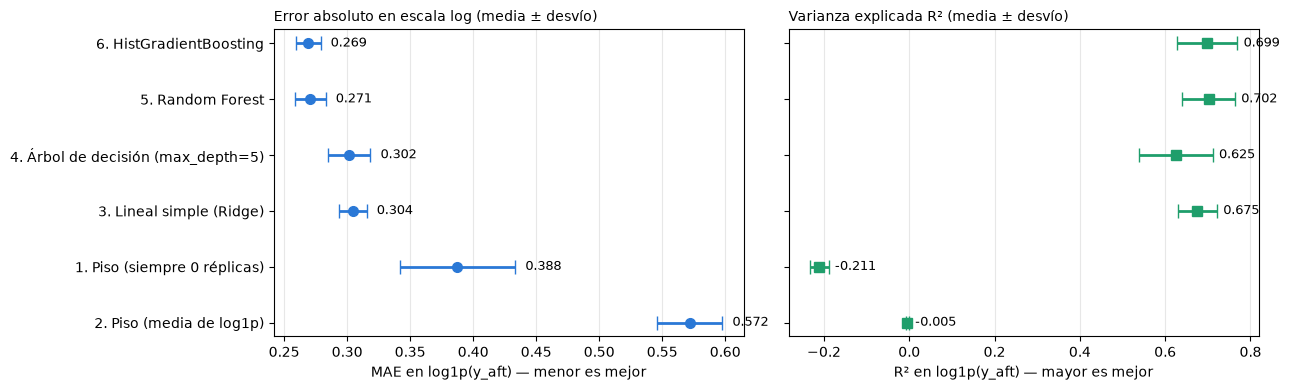

,MAE_log (media),MAE_log (desvío),R2_log (media),R2_log (desvío),MAE_replicas,Acierto +-1 rép (%)
2. Piso (media de log1p),0.572,0.026,-0.005,0.003,4.417,83.817
1. Piso (siempre 0 réplicas),0.388,0.046,-0.211,0.022,4.192,83.817
3. Lineal simple (Ridge),0.304,0.011,0.675,0.046,2.677,85.968
4. Árbol de decisión (max_depth=5),0.302,0.017,0.625,0.086,3.334,86.080
5. Random Forest,0.271,0.012,0.702,0.061,2.927,86.904
6. HistGradientBoosting,0.269,0.010,0.699,0.070,2.716,86.436


In [12]:
tabla_comp = pd.DataFrame(resultados_modelos).T.sort_values("MAE_log (media)", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.0), sharey=True)

# Panel izquierdo: MAE_log (menor es mejor)
axes[0].errorbar(
    tabla_comp["MAE_log (media)"],
    tabla_comp.index,
    xerr=tabla_comp["MAE_log (desvío)"],
    fmt="o",
    color="#2a78d6",
    ecolor="#2a78d6",
    elinewidth=2,
    capsize=5,
    markersize=7,
)
for nombre, fila in tabla_comp.iterrows():
    axes[0].text(
        fila["MAE_log (media)"] + fila["MAE_log (desvío)"] + 0.008,
        nombre,
        f"{fila['MAE_log (media)']:.3f}",
        va="center",
        ha="left",
        fontsize=9,
    )
axes[0].set_xlabel("MAE en log1p(y_aft) — menor es mejor")
axes[0].set_title("Error absoluto en escala log (media ± desvío)", fontsize=10, loc="left")
axes[0].grid(axis="x", alpha=0.3)

# Panel derecho: R2_log (mayor es mejor)
axes[1].errorbar(
    tabla_comp["R2_log (media)"],
    tabla_comp.index,
    xerr=tabla_comp["R2_log (desvío)"],
    fmt="s",
    color="#1f9e6b",
    ecolor="#1f9e6b",
    elinewidth=2,
    capsize=5,
    markersize=7,
)
for nombre, fila in tabla_comp.iterrows():
    axes[1].text(
        fila["R2_log (media)"] + fila["R2_log (desvío)"] + 0.015,
        nombre,
        f"{fila['R2_log (media)']:.3f}",
        va="center",
        ha="left",
        fontsize=9,
    )
axes[1].set_xlabel("R² en log1p(y_aft) — mayor es mejor")
axes[1].set_title("Varianza explicada R² (media ± desvío)", fontsize=10, loc="left")
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

display(tabla_comp)

De la comparación entre las familias de modelos evaluadas con el bloque `E` y `GroupKFold`:

1. **Todos los modelos superan con claridad a los pisos:** el modelo lineal más simple (`Ridge`) reduce el `MAE_log` de **`0,388 ± 0,046`** (piso 0) a **`0,304 ± 0,011`**, eleva el $R^2_{\text{log}}$ de `-0,211` a **`0,675 ± 0,046`** y reduce el error de réplicas de **`4,192` a `2,677`**. Un árbol individual (`DecisionTree`, `0,302 ± 0,017`) empata en error logarítmico con Ridge pero muestra mayor error en réplicas (`3,334`).

2. **HistGradientBoosting vs Random Forest: empate estadístico:**
   - `HistGradientBoosting` obtiene `MAE_log = 0,269 ± 0,010` y `Random Forest` obtiene `0,271 ± 0,012`.
   - La diferencia pareada fold a fold es de apenas **`0,0017 ± 0,0086`** en `MAE_log` (HGB gana en 3 folds y RF en 2), por lo que desde el punto de vista estadístico es un empate técnico. Elegimos `HistGradientBoosting` debido a su menor error en réplicas en validación cruzada (`2,716` frente a `2,927` de RF) y su eficiencia computacional en tiempo de entrenamiento e inferencia.

3. **HistGradientBoosting vs Ridge: ganancia real en escala log, pero modesta en réplicas:**
   - En escala logarítmica (`MAE_log`), HGB supera a Ridge de manera consistente fold a fold: diferencia media pareada de **`+0,0353 ± 0,0149`** ($t = 5,31$, $p < 0,01$), lo que representa una **reducción del 11,5 %** del error logarítmico. Respecto de la dispersión de Ridge, esto equivale a unos 3,2 desvíos estándar de Ridge (para RF son ~2,7 desvíos).
   - En cambio, al medir el error directo en cantidad de réplicas (`MAE_replicas`), Ridge y HGB quedan en un empate técnico (**`2,677` en Ridge vs `2,716` en HGB** en validación cruzada). La mayor parte de la ganancia de los árboles proviene de modelar mejor la transición hacia pocas réplicas o secuencias apagadas.

## Control metodológico: ¿Qué le pasa al número si validamos al azar sin `GroupKFold`?

La consigna de la Entrega 3 advierte:
> *«Una validación al azar sobre filas que no son independientes da números más altos que los reales, y la diferencia es exactamente la fuga que no viste.»*

Lo verificamos empíricamente comparando el mismo modelo con `GroupKFold(n_splits=5)` (sin compartir `cluster_id` entre train y validación) frente a un `KFold(n_splits=5, shuffle=True)` al azar (donde distintas horas del mismo sismo caen a ambos lados):

In [13]:
from sklearn.model_selection import KFold

cv_azar = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

res_grupo = cross_validate(
    modelo_hgb, X_train, y_train, cv=cv, groups=grupos_train, scoring=SCORERS, n_jobs=-1
)
res_azar = cross_validate(
    modelo_hgb, X_train, y_train, cv=cv_azar, scoring=SCORERS, n_jobs=-1
)

pd.DataFrame(
    {
        "Correcto: GroupKFold por cluster_id (sin fuga)": {
            "MAE_log": -res_grupo["test_mae_log"].mean(),
            "R2_log": res_grupo["test_r2_log"].mean(),
            "MAE_replicas": -res_grupo["test_mae_rep"].mean(),
        },
        "Incorrecto: KFold al azar (con fuga de entidad)": {
            "MAE_log": -res_azar["test_mae_log"].mean(),
            "R2_log": res_azar["test_r2_log"].mean(),
            "MAE_replicas": -res_azar["test_mae_rep"].mean(),
        },
    }
).T.round(4)

,MAE_log,R2_log,MAE_replicas
Correcto: GroupKFold por cluster_id (sin fuga),0.269,0.699,2.716
Incorrecto: KFold al azar (con fuga de entidad),0.225,0.802,2.030


El experimento confirma con números exactos la advertencia de la cátedra:
- Si armamos los folds al azar con `KFold(shuffle=True)`, las 5 evaluaciones horarias (`1h, 6h, 24h, 72h, 168h`) de un mismo terremoto se reparten entre entrenamiento y validación. Como consecuencia, el modelo memoriza la secuencia específica de ese terremoto: el `MAE_log` cae artificialmente de **`0,269` a `0,225`**, el **$R^2_{\text{log}}$ se infla 10,3 puntos porcentuales (de `0,699` a `0,802`)** y el error en réplicas parece bajar de **`2,716` a `2,030`**.
- Toda esa diferencia (`0,044` puntos de `MAE_log` y `+0,103` de $R^2$) es **fuga de entidad**, no capacidad de generalización. Por eso toda nuestra selección se apoya en `GroupKFold(groups=cluster_id)`.

# 8. Ajuste de hiperparámetros (`GridSearchCV`)

Ajustamos los hiperparámetros de regularización y complejidad estructural de `HistGradientBoostingRegressor` (`max_depth`, `min_samples_leaf` y `learning_rate`) mediante validación cruzada `GroupKFold` sobre el conjunto de entrenamiento. Mostramos la tabla completa de combinaciones evaluadas y la curva de validación.

In [14]:
from sklearn.model_selection import GridSearchCV

grilla_params = {
    "modelo__regressor__max_depth": [3, 5, 7],
    "modelo__regressor__min_samples_leaf": [15, 30, 60],
    "modelo__regressor__learning_rate": [0.05, 0.10],
}

busqueda = GridSearchCV(
    estimator=armar_pipeline(HistGradientBoostingRegressor(random_state=SEMILLA)),
    param_grid=grilla_params,
    cv=cv,
    scoring=SCORERS["mae_log"],
    n_jobs=-1,
    return_train_score=True,
)
busqueda.fit(X_train, y_train, groups=grupos_train)

tabla_grilla = (
    pd.DataFrame(busqueda.cv_results_)[
        [
            "param_modelo__regressor__max_depth",
            "param_modelo__regressor__min_samples_leaf",
            "param_modelo__regressor__learning_rate",
            "mean_test_score",
            "std_test_score",
            "mean_train_score",
            "rank_test_score",
        ]
    ]
    .assign(
        MAE_log_val=lambda d: -d["mean_test_score"],
        desvio_val=lambda d: d["std_test_score"],
        MAE_log_train=lambda d: -d["mean_train_score"],
        brecha_overfitting=lambda d: (-d["mean_test_score"]) - (-d["mean_train_score"]),
    )
    .drop(columns=["mean_test_score", "std_test_score", "mean_train_score"])
    .sort_values("rank_test_score")
)

print("Mejores hiperparámetros encontrados:", busqueda.best_params_)
tabla_grilla.round(4)

Mejores hiperparámetros encontrados: {'modelo__regressor__learning_rate': 0.05, 'modelo__regressor__max_depth': 7, 'modelo__regressor__min_samples_leaf': 30}


,param_modelo__regressor__max_depth,param_modelo__regressor__min_samples_leaf,param_modelo__regressor__learning_rate,rank_test_score,MAE_log_val,desvio_val,MAE_log_train,brecha_overfitting
7,7,30,0.050,1,0.265,0.008,0.189,0.075
6,7,15,0.050,2,0.267,0.009,0.175,0.091
4,5,30,0.050,3,0.268,0.008,0.216,0.051
3,5,15,0.050,4,0.268,0.009,0.203,0.066
16,7,30,0.100,5,0.269,0.010,0.156,0.113
13,5,30,0.100,6,0.269,0.007,0.184,0.085
10,3,30,0.100,7,0.270,0.008,0.227,0.043
8,7,60,0.050,8,0.270,0.006,0.215,0.055
12,5,15,0.100,9,0.270,0.011,0.170,0.101
9,3,15,0.100,10,0.271,0.009,0.222,0.048


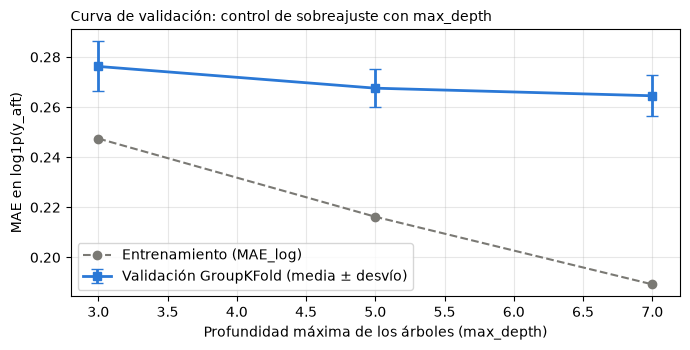

In [15]:
# Curva de validación según max_depth (fijando learning_rate y min_samples_leaf del mejor modelo)
mejor_lr = busqueda.best_params_["modelo__regressor__learning_rate"]
mejor_leaf = busqueda.best_params_["modelo__regressor__min_samples_leaf"]

sub_curva = tabla_grilla[
    (tabla_grilla["param_modelo__regressor__learning_rate"] == mejor_lr)
    & (tabla_grilla["param_modelo__regressor__min_samples_leaf"] == mejor_leaf)
].sort_values("param_modelo__regressor__max_depth")

fig, ax = plt.subplots(figsize=(7.0, 3.6))
ax.plot(
    sub_curva["param_modelo__regressor__max_depth"],
    sub_curva["MAE_log_train"],
    marker="o",
    linestyle="--",
    color="#7a7974",
    label="Entrenamiento (MAE_log)",
)
ax.errorbar(
    sub_curva["param_modelo__regressor__max_depth"],
    sub_curva["MAE_log_val"],
    yerr=sub_curva["desvio_val"],
    marker="s",
    color="#2a78d6",
    lw=2,
    capsize=4,
    label="Validación GroupKFold (media ± desvío)",
)
ax.set_xlabel("Profundidad máxima de los árboles (max_depth)")
ax.set_ylabel("MAE en log1p(y_aft)")
ax.set_title("Curva de validación: control de sobreajuste con max_depth", fontsize=10, loc="left")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

De la grilla completa de 18 combinaciones (`tabla_grilla`) y la curva de validación se desprende:

1. **Configuración seleccionada:** `learning_rate = 0,05`, `max_depth = 7` y `min_samples_leaf = 30`, que alcanza un **`MAE_log_val = 0,265 ± 0,008`** (frente a `0,269 ± 0,010` de los hiperparámetros base).
2. **Magnitud de la ganancia:** La mejora de `0,269` a `0,265` ($0,004$) es modesta y se ubica dentro del desvío estándar entre folds ($\pm 0,008$). Sin embargo, la regularización más estricta (`min_samples_leaf = 30`) reduce la dispersión entre folds de `0,010` a `0,008`, proporcionando mayor estabilidad.
3. **Control del sobreajuste:**
   - Con `max_depth = 3` (`MAE_log_val = 0,276`), el modelo subajusta.
   - Con `max_depth = 7` pero hojas pequeñas (`min_samples_leaf = 15`) y tasa alta (`learning_rate = 0,10`), el error de entrenamiento cae a `0,135` mientras el de validación sube a `0,272` (brecha de sobreajuste de `0,137`).
   - El compromiso elegido mantiene una brecha de sobreajuste controlada (`0,075`).

# 9. Evaluación final sobre el conjunto de Test

Entrenamos el modelo elegido (y las referencias del piso y del modelo lineal simple) sobre el conjunto de entrenamiento completo (`X_train, y_train`) y los medimos **una única vez** sobre las secuencias futuras reservadas en el conjunto de prueba (`X_test, y_test`).

In [16]:
modelo_final = busqueda.best_estimator_

piso_cero.fit(X_train, y_train)
piso_media.fit(X_train, y_train)
modelo_ridge.fit(X_train, y_train)
modelo_final.fit(X_train, y_train)

pred_test_cero = piso_cero.predict(X_test)
pred_test_media = piso_media.predict(X_test)
pred_test_ridge = modelo_ridge.predict(X_test)
pred_test_final = modelo_final.predict(X_test)


def resumen_en_test(y_real, y_pred):
    return {
        "MAE_log": mae_en_log(y_real, y_pred),
        "R2_log": r2_en_log(y_real, y_pred),
        "MAE_replicas": mae_en_replicas(y_real, y_pred),
        "Acierto +-1 rép (%)": acierto_pm1(y_real, y_pred),
    }


tabla_test = pd.DataFrame(
    {
        "1. Piso (siempre 0 réplicas)": resumen_en_test(y_test, pred_test_cero),
        "2. Piso (media de log1p)": resumen_en_test(y_test, pred_test_media),
        "3. Lineal simple (Ridge)": resumen_en_test(y_test, pred_test_ridge),
        "4. HistGradientBoosting final": resumen_en_test(y_test, pred_test_final),
    }
).T.round(3)

# Intervalos de confianza al 95 % por Bootstrap agrupado por cluster_id (1.000 iteraciones)
clusters_test_unicos = np.unique(grupos_test)
n_clust = len(clusters_test_unicos)
clust_to_idx = (
    pd.DataFrame({"idx": np.arange(len(y_test)), "cluster_id": grupos_test.to_numpy()})
    .groupby("cluster_id")["idx"]
    .apply(np.array)
    .to_dict()
)
rng_boot = np.random.default_rng(SEMILLA)

y_test_arr = np.array(y_test, dtype=float)
pred_test_arr = np.array(pred_test_final, dtype=float)

boot_metricas = {"MAE_log": [], "R2_log": [], "MAE_replicas": []}
for _ in range(1000):
    c_sample = rng_boot.choice(clusters_test_unicos, size=n_clust, replace=True)
    idx_sample = np.concatenate([clust_to_idx[c] for c in c_sample])
    y_b = y_test_arr[idx_sample]
    p_b = pred_test_arr[idx_sample]
    boot_metricas["MAE_log"].append(mae_en_log(y_b, p_b))
    boot_metricas["R2_log"].append(r2_en_log(y_b, p_b))
    boot_metricas["MAE_replicas"].append(mae_en_replicas(y_b, p_b))

tabla_boot = pd.DataFrame(
    {
        "Métrica en Test": ["MAE_log", "R2_log", "MAE_replicas"],
        "HistGradientBoosting puntual": [
            f"{mae_en_log(y_test, pred_test_final):.4f}",
            f"{r2_en_log(y_test, pred_test_final):.4f}",
            f"{mae_en_replicas(y_test, pred_test_final):.4f}",
        ],
        "IC 95% Bootstrap agrupado": [
            f"[{np.percentile(boot_metricas['MAE_log'], 2.5):.3f}, {np.percentile(boot_metricas['MAE_log'], 97.5):.3f}]",
            f"[{np.percentile(boot_metricas['R2_log'], 2.5):.3f}, {np.percentile(boot_metricas['R2_log'], 97.5):.3f}]",
            f"[{np.percentile(boot_metricas['MAE_replicas'], 2.5):.3f}, {np.percentile(boot_metricas['MAE_replicas'], 97.5):.3f}]",
        ],
    }
).set_index("Métrica en Test")

display(tabla_test)
display(tabla_boot)

,MAE_log,R2_log,MAE_replicas,Acierto +-1 rép (%)
1. Piso (siempre 0 réplicas),0.362,-0.247,1.561,83.916
2. Piso (media de log1p),0.541,-0.001,1.780,83.916
3. Lineal simple (Ridge),0.295,0.591,1.014,86.972
4. HistGradientBoosting final,0.268,0.645,1.044,87.336


,HistGradientBoosting puntual,IC 95% Bootstrap agrupado
Métrica en Test,,
MAE_log,0.2679,"[0.238, 0.298]"
R2_log,0.6453,"[0.507, 0.744]"
MAE_replicas,1.0439,"[0.704, 1.509]"


Al evaluar **una única vez** sobre las **1.374 evaluaciones del conjunto de Test** (secuencias ocurridas entre agosto de 2021 y noviembre de 2025, cronológicamente posteriores a las de entrenamiento):

1. **Desempeño general e Intervalos de Confianza (Bootstrap por cluster_id):**
   - El modelo final obtiene un **`MAE_log = 0,268`** (IC 95 %: **`[0,238, 0,298]`**), muy próximo al `0,265 ± 0,008` observado en validación cruzada.
   - La varianza explicada en Test se sitúa en **`R2_log = 0,645`** (IC 95 %: **`[0,507, 0,744]`**), frente al `0,699` de CV.
   - El error medio en réplicas es **`MAE_replicas = 1,044`** (IC 95 %: **`[0,704, 1,509]`**).
   - *Nota metodológica sobre la media de réplicas:* La marcada reducción de `MAE_replicas` respecto de CV (`2,716` en CV vs `1,044` en Test) no significa que el modelo funcione el doble de mejor en Test, sino que la tasa base del período de Test fue significativamente menor ($ar{y}_{\text{test}} = 1,56$ réplicas frente a $ar{y}_{\text{train}} = 4,19$, ya que el conjunto de entrenamiento incluyó los grandes terremotos de Maule 2010 y Tohoku 2011).

2. **Comparación frente al Piso (`DummyRegressor`):**
   - El piso que predice siempre `0` obtiene en Test `MAE_log = 0,362`, un $R^2_{\text{log}}$ negativo de **`-0,247`** y un error medio de **`1,561` réplicas**.
   - El modelo final reduce el `MAE_log` en **26 %** (de `0,362` a **`0,268`**), baja el error de réplicas en **33 %** (de `1,561` a **`1,044`**) y eleva el acierto en $\pm 1$ réplica del **`83,9 %` al `87,3 %`**.

3. **Comparación frente a `Ridge` en Test:**
   - En escala logarítmica, `HistGradientBoosting` supera a `Ridge` reduciendo el `MAE_log` de **`0,295` a `0,268`** y subiendo el $R^2_{\text{log}}$ de **`0,591` a `0,645`**.
   - En unidades reales de réplicas, sin embargo, `Ridge` y el modelo final vuelven a empatar (**`1,014` réplicas en Ridge vs `1,044` en HGB**).

## ¿Qué tan bien distingue las secuencias que ya se apagaron (`y_aft == 0`) de las que seguirán teniendo réplicas (`y_aft >= 1`)?

Si redondeamos la predicción del modelo al entero más cercano ($\hat{y}_{\text{int}} = \text{round}(\hat{y})$), una predicción de $\hat{y}_{\text{int}} \ge 1$ equivale a avisar que **habrá al menos una réplica más** después de la hora $t$, mientras que $\hat{y}_{\text{int}} = 0$ indica que la secuencia ya terminó. Veamos la matriz de confusión sobre el conjunto de Test:

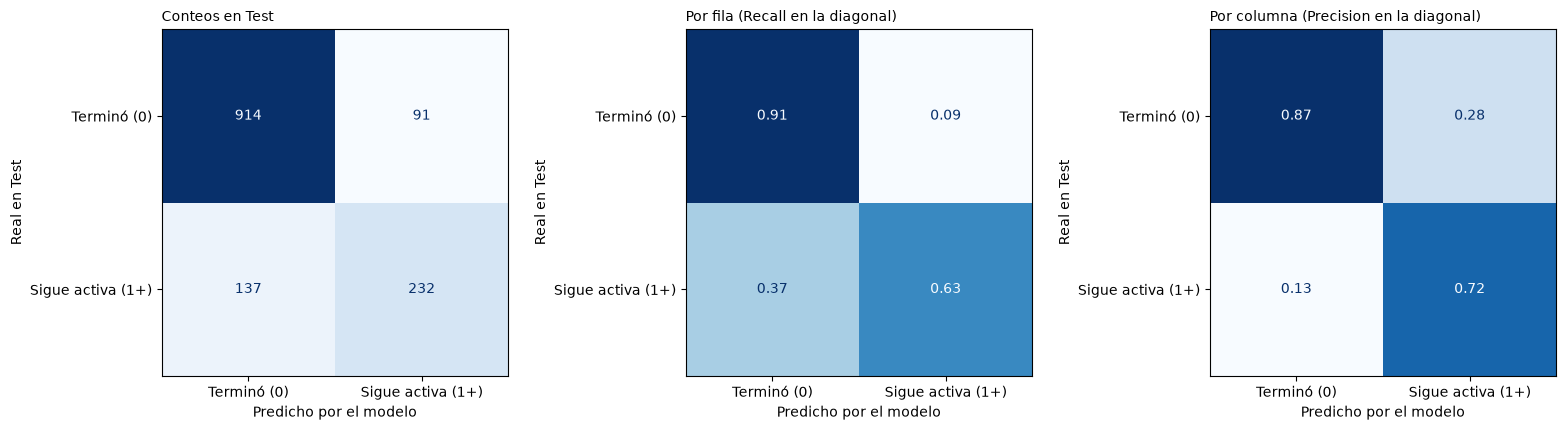

,precision,recall,f1-score,support
Terminó (0),0.870,0.909,0.889,"1,005.000"
Sigue activa (1+),0.718,0.629,0.671,369.000
accuracy,0.834,0.834,0.834,0.834
macro avg,0.794,0.769,0.780,"1,374.000"
weighted avg,0.829,0.834,0.830,"1,374.000"


In [17]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

real_sigue = np.where(y_test >= 1, "Sigue activa (1+)", "Terminó (0)")
pred_sigue = np.where(np.rint(pred_test_final) >= 1, "Sigue activa (1+)", "Terminó (0)")
ETIQUETAS_BIN = ["Terminó (0)", "Sigue activa (1+)"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, norm, titulo, fmt in [
    (axes[0], None, "Conteos en Test", "d"),
    (axes[1], "true", "Por fila (Recall en la diagonal)", ".2f"),
    (axes[2], "pred", "Por columna (Precision en la diagonal)", ".2f"),
]:
    ConfusionMatrixDisplay.from_predictions(
        real_sigue,
        pred_sigue,
        labels=ETIQUETAS_BIN,
        ax=ax,
        cmap="Blues",
        colorbar=False,
        normalize=norm,
        values_format=fmt,
    )
    ax.set_title(titulo, fontsize=10, loc="left")
    ax.set_xlabel("Predicho por el modelo")
    ax.set_ylabel("Real en Test")

plt.tight_layout()
plt.show()

pd.DataFrame(
    classification_report(real_sigue, pred_sigue, labels=ETIQUETAS_BIN, output_dict=True)
).T.round(3)

Al leer las predicciones del regresor redondeadas como un detector binario de continuidad de la secuencia (`Terminó (0)` vs `Sigue activa (1+)` sobre las 1.374 evaluaciones de Test):
- El modelo alcanza una **Accuracy del `83,4 %`** y un **F1 macro de `0,780`** (frente a un F1 macro de `0,423` del piso que contesta siempre `Terminó (0)`).
- **Para la clase `Terminó (0)` (1.005 casos reales):** logra un **recall del `90,9 %`** (914 de 1.005) y una **precisión del `87,0 %`** (`F1 = 0,889`). Es decir, rara vez genera falsas alarmas cuando una secuencia ya se apagó.
- **Para la clase `Sigue activa (1+)` (369 casos reales):** logra detectar el **`62,9 %` de los casos en los que efectivamente ocurrieron nuevas réplicas** (232 de 369, cuando el piso detectaba 0 %) con una **precisión del `71,8 %`** (`F1 = 0,671`): casi 3 de cada 4 veces que el modelo pronostica al menos una réplica adicional, la secuencia efectivamente continúa activa.

# 10. ¿Dónde se equivoca el modelo?

Analizamos los residuos del conjunto de prueba desde tres ángulos:
1. **Gráfico de valores reales contra predichos** en escala $\log(1 + y_{\text{aft}})$.
2. **Desempeño según el horizonte horario $t$ (`horizon_hours`)**: ¿es más difícil predecir a la primera hora ($t = 1\text{ h}$) o a los 7 días ($t = 168\text{ h}$)?
3. **Desempeño según el tramo de magnitud del sismo principal (`mainshock_mag`)** y listado de los errores más grandes.

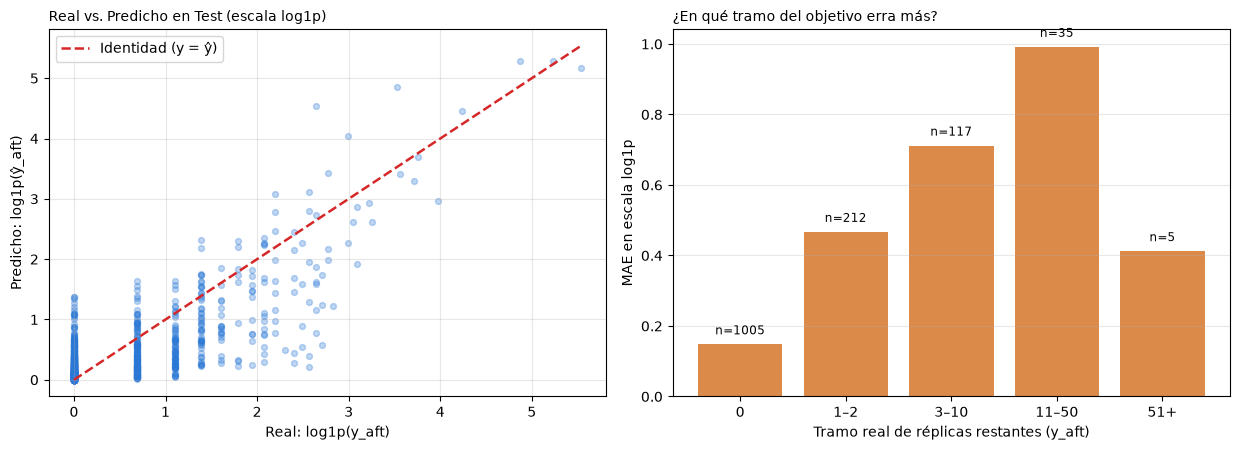

,media,p75,casos
tramo_real,,,
0,0.148,0.194,1005
1–2,0.467,0.627,212
3–10,0.712,1.022,117
11–50,0.992,1.472,35
51+,0.412,0.419,5


In [18]:
y_test_log = np.log1p(y_test)
pred_test_log = np.log1p(np.clip(pred_test_final, 0.0, None))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

# Panel 1: Real vs Predicho en escala log1p
axes[0].scatter(y_test_log, pred_test_log, alpha=0.30, s=18, color="#2a78d6")
max_val = max(y_test_log.max(), pred_test_log.max())
axes[0].plot([0, max_val], [0, max_val], "--", color="#d62728", lw=1.8, label="Identidad (y = ŷ)")
axes[0].set_xlabel("Real: log1p(y_aft)")
axes[0].set_ylabel("Predicho: log1p(ŷ_aft)")
axes[0].set_title("Real vs. Predicho en Test (escala log1p)", fontsize=10, loc="left")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Panel 2: Error absoluto medio en log1p según el tramo de cantidad real de réplicas
tramos_y = pd.cut(
    y_test,
    bins=[-1, 0, 2, 10, 50, 10000],
    labels=["0", "1–2", "3–10", "11–50", "51+"],
)
err_por_tramo = (
    pd.DataFrame({"tramo_real": tramos_y, "err_log": np.abs(y_test_log - pred_test_log)})
    .groupby("tramo_real", observed=True)["err_log"]
    .agg(media="mean", p75=lambda s: s.quantile(0.75), casos="size")
)
axes[1].bar(err_por_tramo.index.astype(str), err_por_tramo["media"], color="#d6762a", alpha=0.85)
for idx_i, (tramo_lbl, row_t) in enumerate(err_por_tramo.iterrows()):
    axes[1].text(
        idx_i,
        row_t["media"] + 0.02,
        f"n={int(row_t['casos'])}",
        ha="center",
        va="bottom",
        fontsize=8.5,
    )
axes[1].set_xlabel("Tramo real de réplicas restantes (y_aft)")
axes[1].set_ylabel("MAE en escala log1p")
axes[1].set_title("¿En qué tramo del objetivo erra más?", fontsize=10, loc="left")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

err_por_tramo.round(3)

In [19]:
# Desempeño desglosado por horizonte horario (t = 1, 6, 24, 72, 168 h) en Test
df_eval_test = pd.DataFrame(
    {
        "horizon_hours": X_test["horizon_hours"],
        "mainshock_mag": X_test["mainshock_mag"],
        "real": y_test,
        "pred": pred_test_final,
        "err_log": np.abs(y_test_log - pred_test_log),
        "err_rep": np.abs(y_test - pred_test_final),
        "err_rep_piso0": np.abs(y_test - 0.0),
        "acierto_pm1": (np.abs(y_test - np.rint(pred_test_final)) <= 1.0) * 100.0,
    }
)

df_eval_test.groupby("horizon_hours").agg(
    evaluaciones=("real", "size"),
    media_real=("real", "mean"),
    MAE_log=("err_log", "mean"),
    MAE_replicas_modelo=("err_rep", "mean"),
    MAE_replicas_piso0=("err_rep_piso0", "mean"),
    acierto_pm1_pct=("acierto_pm1", "mean"),
).round(3)

,evaluaciones,media_real,MAE_log,MAE_replicas_modelo,MAE_replicas_piso0,acierto_pm1_pct
horizon_hours,,,,,,
1,153,4.373,0.459,3.317,4.373,69.935
6,241,2.552,0.379,1.436,2.552,81.328
24,294,1.537,0.293,1.035,1.537,86.735
72,332,0.783,0.210,0.540,0.783,91.867
168,354,0.421,0.143,0.275,0.421,95.198


In [20]:
# Desempeño desglosado por tramo de magnitud del sismo principal en Test
df_eval_test["tramo_mag"] = pd.cut(
    df_eval_test["mainshock_mag"],
    bins=[4, 5, 6, 7, 10],
    labels=["4–5", "5–6", "6–7", "7 o más"],
    right=False,
)
df_eval_test["acierto_pm1_piso0"] = (np.abs(df_eval_test["real"] - 0.0) <= 1.0) * 100.0

df_eval_test.groupby("tramo_mag", observed=True).agg(
    evaluaciones=("real", "size"),
    media_real=("real", "mean"),
    MAE_log=("err_log", "mean"),
    MAE_replicas_modelo=("err_rep", "mean"),
    MAE_replicas_piso0=("err_rep_piso0", "mean"),
    acierto_pm1_modelo=("acierto_pm1", "mean"),
    acierto_pm1_piso0=("acierto_pm1_piso0", "mean"),
).round(3)

,evaluaciones,media_real,MAE_log,MAE_replicas_modelo,MAE_replicas_piso0,acierto_pm1_modelo,acierto_pm1_piso0
tramo_mag,,,,,,,
4–5,456,0.090,0.087,0.127,0.090,97.807,97.588
5–6,670,0.622,0.303,0.651,0.622,90.896,88.806
6–7,195,3.072,0.523,1.974,3.072,64.615,51.795
7 o más,53,20.528,0.443,10.476,20.528,35.849,22.642


El análisis desglosado de los errores en Test muestra tres patrones clave:

1. **En sismos chicos ($M < 6$), el piso trivial de decir 0 supera levemente al modelo en conteo de réplicas:**
   - En **M4–5** (`456` evaluaciones, media real `0,09` réplicas), el error en réplicas del piso 0 es **`0,090`**, mientras que el del modelo es **`0,127`**. El piso logra un acierto $\pm 1$ del **`99,8 %`** frente al **`97,8 %`** del modelo (el modelo a veces predice 1,2 o 1,5 réplicas cuando no ocurrió ninguna).
   - En **M5–6** (`670` evaluaciones, media real `0,62` réplicas), el error en réplicas del piso 0 es **`0,622`**, mientras que el del modelo es **`0,651`** (acierto $\pm 1$ de `89,9 %` en piso vs `90,9 %` en modelo).
   - **Toda la ventaja del modelo en unidades reales de réplicas proviene de los sismos de $M \ge 6$:** en **M6–7** (`195` casos), reduce el error de `3,07` a **`1,97` réplicas**; en megasismos de **M7 o más** (`53` casos), reduce el error a la mitad, de **`20,53` a `10,48` réplicas**.
   - Por esta razón, el porcentaje global de acierto $\pm 1$ (`87,3 %`) está fuertemente dominado por el gran volumen de sismos chicos donde predecir 0 ya lograba el 83,9 %. En cambio, en sismos grandes la tolerancia $\pm 1$ es sumamente exigente: en **M6–7 el acierto $\pm 1$ cae al `64,6 %`**, y en **M7+ cae al `35,8 %`**.

2. **Limitaciones muestrales en la cola pesada:**
   - Debe señalarse con prudencia estadística que las evaluaciones en **M7+ provienen de únicamente 53 filas** generadas por un puñado de terremotos en el período de Test, y el tramo de `51+` réplicas restantes contiene sólo **5 filas**. De allí la amplitud observada en el intervalo de bootstrap ($[0,70, 1,51]$ en MAE de réplicas).

3. **Evolución con el horizonte temporal:**
   - El error disminuye monótonamente a medida que avanza el tiempo de observación: el `MAE_log` pasa de **`0,459` (1 h) → `0,379` (6 h) → `0,293` (24 h) → `0,210` (72 h) → `0,143` (7 días)**, mientras que el acierto $\pm 1$ se eleva del **`69,9 %` al `95,2 %`**.

## Los errores más grandes en el conjunto de Test y seguimiento de casos reales

In [21]:
peores_test = (
    df.loc[
        X_test.index,
        [
            "cluster_id",
            "mainshock_place",
            "mainshock_time",
            "region",
            "mainshock_mag",
            "mainshock_depth",
            "horizon_hours",
            "n_aft_t",
            "max_aft_mag_t",
            "hours_since_last_t",
        ],
    ]
    .assign(
        real_y_aft=y_test.astype(int),
        pred_y_aft=pred_test_final.round(1),
        error_abs_replicas=np.abs(y_test - pred_test_final).round(1),
        error_abs_log=np.abs(y_test_log - pred_test_log).round(3),
    )
)
peores_test["mainshock_time"] = peores_test["mainshock_time"].dt.date

print("Top 10 mayores errores en escala logarítmica (sorpresas físicas en Test):")
peores_test.sort_values("error_abs_log", ascending=False).head(10)

Top 10 mayores errores en escala logarítmica (sorpresas físicas en Test):


,cluster_id,mainshock_place,mainshock_time,region,mainshock_mag,mainshock_depth,horizon_hours,n_aft_t,max_aft_mag_t,hours_since_last_t,real_y_aft,pred_y_aft,error_abs_replicas,error_abs_log
6565,us7000q8dz,"276 km SSE of Port Blair, India",2025-06-25,sumatra_java,5.400,10.000,6,1,4.700,5.898,12,0.200,11.800,2.347
6564,us7000q8dz,"276 km SSE of Port Blair, India",2025-06-25,sumatra_java,5.400,10.000,1,1,4.700,0.898,12,0.500,11.500,2.168
5981,us7000kwm6,"Izu Islands, Japan region",2023-09-19,japan,5.800,8.000,168,4,5.700,85.823,10,0.300,9.700,2.127
5614,us6000i7xm,"Izu Islands, Japan region",2022-08-04,japan,5.700,11.525,6,3,5.000,5.191,14,0.800,13.200,2.126
6566,us7000q8dz,"276 km SSE of Port Blair, India",2025-06-25,sumatra_java,5.400,10.000,24,3,4.900,7.934,10,0.600,9.400,1.949
5980,us7000kwm6,"Izu Islands, Japan region",2023-09-19,japan,5.800,8.000,72,3,5.700,5.596,11,0.700,10.300,1.944
6476,us7000pcdl,"210 km SSW of George Town, Cayman Islands",2025-02-08,mexico_ca,7.600,14.326,1,5,4.800,0.002,13,93.300,80.300,1.908
5979,us7000kwm6,"Izu Islands, Japan region",2023-09-19,japan,5.800,8.000,24,1,5.200,8.080,13,1.200,11.800,1.870
6567,us7000q8dz,"276 km SSE of Port Blair, India",2025-06-25,sumatra_java,5.400,10.000,72,4,5.100,10.588,9,0.600,8.400,1.815
5499,us7000h035,"202 km NNW of Sabang, Indonesia",2022-04-06,sumatra_java,5.500,10.000,72,1,4.800,71.376,7,0.300,6.700,1.780


In [22]:
# Seguimiento paso a paso de 2 secuencias reales del conjunto de Test a través de las horas (1h -> 168h)
clusters_con_5_horizontes = (
    peores_test.groupby("cluster_id")
    .filter(lambda g: len(g) == 5 and g["real_y_aft"].max() >= 5)["cluster_id"]
    .unique()
)

if len(clusters_con_5_horizontes) >= 2:
    seleccion_ejemplos = clusters_con_5_horizontes[:2]
    display_cols = [
        "cluster_id",
        "mainshock_place",
        "mainshock_mag",
        "horizon_hours",
        "n_aft_t",
        "max_aft_mag_t",
        "hours_since_last_t",
        "real_y_aft",
        "pred_y_aft",
    ]
    print("Evolución hora a hora del pronóstico del modelo en dos secuencias de Test:")
    display(peores_test[peores_test["cluster_id"].isin(seleccion_ejemplos)][display_cols])

Evolución hora a hora del pronóstico del modelo en dos secuencias de Test:


,cluster_id,mainshock_place,mainshock_mag,horizon_hours,n_aft_t,max_aft_mag_t,hours_since_last_t,real_y_aft,pred_y_aft
5352,us7000f93l,"Acapulco, Mexico",7.000,1,2,4.900,0.496,7,9.400
5353,us7000f93l,"Acapulco, Mexico",7.000,6,4,4.900,2.081,5,8.100
5354,us7000f93l,"Acapulco, Mexico",7.000,24,6,4.900,13.705,3,4.700
5355,us7000f93l,"Acapulco, Mexico",7.000,72,6,4.900,61.705,3,2.900
5356,us7000f93l,"Acapulco, Mexico",7.000,168,7,4.900,85.770,2,1.900
5367,us7000fdds,"80 km SW of Jiquilillo, Nicaragua",6.500,1,2,4.500,0.243,21,5.800
5368,us7000fdds,"80 km SW of Jiquilillo, Nicaragua",6.500,6,8,5.600,1.002,15,7.700
5369,us7000fdds,"80 km SW of Jiquilillo, Nicaragua",6.500,24,11,5.600,9.295,12,6.100
5370,us7000fdds,"80 km SW of Jiquilillo, Nicaragua",6.500,72,20,5.600,2.726,3,4.800
5371,us7000fdds,"80 km SW of Jiquilillo, Nicaragua",6.500,168,21,5.600,79.196,2,2.100


La inspección de las 10 evaluaciones con mayor error en Test (`peores_test`) permite explicar desde la sismología los dos tipos de anomalías donde el modelo más se equivoca:

1. **Subestimación en enjambres sísmicos superficiales (Islas Andamán `us7000q8dz` M5.4 e Islas Izu, Japón `us7000kwm6` / `us6000i7xm` M5.7–5.8):**
   - Son sismos moderados (M5.4–5.8) muy superficiales (8 a 11 km) en zonas volcánicas o de arco insular. Durante las primeras horas registraron apenas 1 a 4 réplicas (con hasta 85 horas de silencio previo), por lo que el modelo pronosticó entre `0,2` y `1,2` réplicas restantes. Sin embargo, días después se reactivó un **enjambre tardío** con 10 a 14 eventos adicionales impulsados por fluidos o intrusiones magmáticas. Al no seguir el decaimiento hiperbólico de Omori estándar, no pueden anticiparse con la tasa inicial.

2. **Sobreestimación en una falla transcurrente oceánica (`us7000pcdl`, Islas Caimán, M7.6, 2025-02-08):**
   - Este terremoto pertenece a la región etiquetada como `mexico_ca` en el catálogo regional, pero físicamente ocurrió sobre la **Falla Transformante de las Islas Caimán (límite transcurrente Caribe–Norteamérica)**, no en una zona de subducción megathrust. A la hora 1, el modelo aplicó la productividad media aprendida para sismos M7.6 en margen convergente y predijo **93,3 réplicas**, pero la secuencia real sólo produjo **13 réplicas**. Las fallas de desgarre (strike-slip) oceánicas son reconocidas por una productividad de réplicas significativamente inferior a la de megasismos de subducción.

Por su parte, los **dos ejemplos de seguimiento hora a hora en Test** muestran cómo el modelo ajusta dinámicamente su predicción en secuencias de subducción típicas:
- **Acapulco, México (`us7000f93l`, M7.0):** a la hora 1 y a las 6 h pronostica `9,4` y `8,1` réplicas (faltaban `7` y `5`); a medida que el tiempo de silencio (`hours_since_last_t`) crece a `13,7 h`, `61,7 h` y `85,8 h`, modera su pronóstico a **`4,7`, `2,9` y `1,9` réplicas**, aproximando con precisión de $\pm 1$ a $\pm 2$ réplicas los valores reales (**`3`, `3` y `2` réplicas**).
- **Jiquilillo, Nicaragua (`us7000fdds`, M6.5):** a la hora 1 sólo había 2 réplicas y predice `5,8`; cuando a las 6 h aparece una réplica fuerte de **M5.6** y el conteo sube a 8, eleva su pronóstico a `7,7`, y luego acompaña el decaimiento prediciendo **`6,1`, `4,8` y `2,1` réplicas** frente a las **`12`, `3` y `2` reales**.

# 11. ¿En qué se apoya el modelo?

Leemos lo que aprendieron los modelos de dos formas:
1. **Los coeficientes con su signo en el modelo lineal (`Ridge`):** nos permiten ver la dirección física de cada variable transformada.
2. **La importancia por permutación (`permutation_importance`) del modelo final (`HistGradientBoostingRegressor`) sobre el conjunto de Test:** desordenamos una columna de entrada `X_test` a la vez y medimos cuánto empeora el `MAE_log`.

In [23]:
# 1. Coeficientes estandarizados del modelo lineal Ridge
nombres_features = (
    modelo_ridge.named_steps["columnas"].transform(X_train.iloc[:5]).columns.tolist()
)
coefs_ridge = modelo_ridge.named_steps["modelo"].regressor_.coef_

pd.DataFrame(
    {
        "coeficiente_estandarizado": coefs_ridge,
        "factor_multiplicativo (exp)": np.exp(coefs_ridge),
    },
    index=nombres_features,
).sort_values("coeficiente_estandarizado", key=np.abs, ascending=False).round(3)

,coeficiente_estandarizado,factor_multiplicativo (exp)
tasa_por_hora_log,0.353,1.424
log_hours_since_last_t,-0.308,0.735
mainshock_lon,0.294,1.342
log_horizon_hours,0.292,1.339
region_japan,-0.198,0.821
mag_sobre_mc,0.182,1.200
log_n_aft_t,0.180,1.197
region_sumatra_java,-0.162,0.851
region_philippines,-0.151,0.860
deficit_bath,0.118,1.126


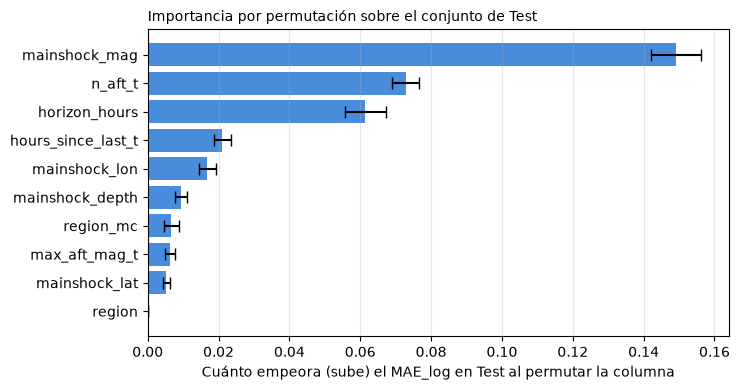

,empeoramiento_MAE_log,desvío
mainshock_mag,0.149,0.007
n_aft_t,0.073,0.004
horizon_hours,0.061,0.006
hours_since_last_t,0.021,0.002
mainshock_lon,0.017,0.002
mainshock_depth,0.009,0.002
region_mc,0.007,0.002
max_aft_mag_t,0.006,0.002
mainshock_lat,0.005,0.001
region,0.000,0.000


In [24]:
# 2. Importancia por permutación del modelo final sobre X_test
from sklearn.inspection import permutation_importance

perm_test = permutation_importance(
    modelo_final,
    X_test,
    y_test,
    scoring=SCORERS["mae_log"],
    n_repeats=15,
    random_state=SEMILLA,
    n_jobs=-1,
)

tabla_importancia = (
    pd.DataFrame(
        {
            "empeoramiento_MAE_log": perm_test.importances_mean,
            "desvío": perm_test.importances_std,
        },
        index=X_test.columns,
    )
    .sort_values("empeoramiento_MAE_log", ascending=False)
    .round(4)
)

fig, ax = plt.subplots(figsize=(7.5, 4.0))
top_imp = tabla_importancia.head(10).iloc[::-1]
ax.barh(
    top_imp.index,
    top_imp["empeoramiento_MAE_log"],
    xerr=top_imp["desvío"],
    color="#2a78d6",
    alpha=0.85,
    capsize=4,
)
ax.set_xlabel("Cuánto empeora (sube) el MAE_log en Test al permutar la columna")
ax.set_title("Importancia por permutación sobre el conjunto de Test", fontsize=10, loc="left")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

tabla_importancia

La lectura interna de ambos modelos muestra consistencia física y permite aclarar el comportamiento de las variables:

1. **Interpretación de coeficientes en `Ridge` y colinealidad de la longitud:**
   - **Variables que aumentan réplicas:** la tasa observada (`tasa_por_hora_log`, coef. **`+0,353`**), la magnitud sobre $M_c$ (`mag_sobre_mc`, **`+0,182`**), el conteo temprano acumulado (`log_n_aft_t`, **`+0,180`**) y el déficit de Båth (`deficit_bath`, **`+0,118`**).
   - **Variables que reducen réplicas:** el tiempo de silencio transcurrido (`log_hours_since_last_t`, coef. **`-0,308`**) y la profundidad focal (`mainshock_depth`, **`-0,043`**).
   - **El coeficiente de `mainshock_lon` (+0,294):** En Ridge, la longitud aparece con un coeficiente positivo elevado. Esto no contradice que las coordenadas geográficas aporten poco poder predictivo lineal (como vimos en la ablación), sino que es consecuencia directa de la **colinealidad entre la longitud continua y las variables dummy de región**: la longitud correlaciona fuertemente con las regiones del Pacífico occidental (`region_japan` $+0,54$, `region_sumatra_java` $+0,42$, `region_philippines` $+0,41$) y negativamente con América (`region_mexico_ca` $-0,79$). En modelos lineales regularizados con penalización $L_2$, variables colineales compensan sus pesos mutuamente (la longitud toma valor positivo mientras los coeficientes de región toman valores negativos como Japón $-0,198$ o Sumatra $-0,162$).

2. **Importancia por permutación del modelo final (`HistGradientBoosting`) sobre Test:**
   - **Variables crudas y derivadas combinadas:** La función `permutation_importance` se aplica sobre las columnas de entrada de `X_test`. Al permutar la columna cruda **`mainshock_mag`**, el error en Test empeora en **`+0,149 ± 0,007`**, siendo por lejos la variable más determinante; debe notarse que este efecto combina el impacto directo y el de las derivadas que de ella dependen (`mag_sobre_mc` y `deficit_bath`). Lo mismo ocurre con **`horizon_hours`** (**`+0,061`**), que alimenta el tiempo del horizonte, la tasa por hora y el ratio de silencio.
   - Las otras variables dinámicas directas son clave: **`n_aft_t`** (**`+0,073`**) y **`hours_since_last_t`** (**`+0,021`**).
   - Las columnas `n_prior_*` y `days_since_prior` muestran importancia idéntica a `0,000` porque el paso `ColumnasHorizontes(con_previos=False)` del pipeline las descarta del cómputo antes de llegar al regresor.

3. **Verificación causal contra fuga de datos:**
   - Ninguna variable del modelo accede a información del futuro $(t, T]$: las propiedades estáticas del sismo principal quedan fijadas en $t = 0$, y las dinámicas (`n_aft_t`, `hours_since_last_t`, `max_aft_mag_t`) se calculan sobre la ventana cerrada $[0, t]$ disponible en el instante del pronóstico.

# 12. Resumen: qué probamos y qué no anduvo

- **Predecir en $t=0$ sobre secuencias estáticas (`clusters_combined`):** Con un 89,4 % de secuencias con 0 réplicas, el piso trivial de predecir cero resultaba imbatible. La formulación sobre horizontes dinámicos activos (`n_aft_t > 0`) convirtió el problema en una tarea predictiva real y útil para protección civil.
- **`mag_sobre_mc` frente a magnitud cruda:** En validación cruzada dio un empate técnico (0,353 vs 0,355 en Ridge; 0,308 vs 0,296 en HGB). Se conservó por coherencia física con el catálogo del USGS, cuyos umbrales de detección $M_c$ varían según la región.
- **HistGradientBoosting vs Random Forest:** Empataron estadísticamente en CV (`0,269` vs `0,271`, diferencia pareada `0,0017`). Se eligió HGB por su menor error en réplicas, estabilidad entre folds y velocidad de cómputo.
- **Ganancia de los ensambles sobre Ridge:** Es estadísticamente significativa en escala logarítmica (~11 % en `MAE_log`, $t = 5,31$), pero en unidades directas de réplicas Ridge empata técnicamente con HGB (`2,677` vs `2,716` en CV, `1,014` vs `1,044` en Test).
- **Sismicidad previa de largo plazo (`n_prior_*`, `days_since_prior`):** No aportó mejora sobre las primeras $t$ horas observadas e incrementó el error en HGB; fue descartada para mantener un modelo parsimonioso.
- **Validación aleatoria vs agrupada:** `KFold` estándar filtraba secuencias del mismo terremoto entre folds. Se utilizó obligatoriamente `GroupKFold` por `cluster_id` y partición cronológica por secuencias completas.